___
# FIGURE 3BCD *Plot* inpatient pain decoding
Shirvalkar et al., Nature Medicine 2026

This notebook summarizes:
- cohort-level Lasso performance (Figure 3B, ground truth vs predicted pain scores)
- cohort-level LDA performance (Figure 3C, true positive rate vs false positive rate)
- P3 feature prominence in brain regions across pain decoding models. (Figure 3D)

Inputs:
- main_dir: directory of repository so files can be loaded/saved
  
Outputs (Figure 3 subpanels made):
- Figure 3B: scatter plot of ground truth vs predicted pain scores across all participants
- Figure 3C: ROC for linear discriminant analysis of predicted pain across all participants
- Figure 3D: Side-by-side bar plot of left/right hemisphere regions
  _________

### Repository root (resolved automatically; set `NATMED_REPO` to override)

In [1]:
import os
# Repository root: defaults to the parent of python_code/, i.e. this notebook's
# grandparent folder. Override by setting the NATMED_REPO environment variable
# or replacing this line with an explicit path to your local copy.
main_dir = os.environ.get('NATMED_REPO',
    os.path.abspath(os.path.join(os.getcwd(), os.pardir))) + '/'


### Figures 3B & 3C configuration
For cohort-level LASSO and LDA pain decoding plots, SET which pain metric and time window is used.

The models below are those shown in Shirvalkar et al., 2026 (Figure 3B and 3C). All ten are significant against their permutation null.

In [2]:
model_config = {
    'P1': {'LASSO': ('nrs_s0', 'five_minute'),
           'LDA'  : ('nrs_s0', 'five_minute')},

    'P2': {'LASSO': ('unpleasantness_vas_s0', 'one_minute'),
           'LDA'  : ('relief_s0', 'ten_minute')},

    'P3': {'LASSO': ('intensity_vas_s0', 'thirty_minute'),
           'LDA'  : ('intensity_vas_s0', 'five_minute')},

    'P4': {'LASSO': ('nrs_s0', 'ten_minute'),
           'LDA'  : ('intensity_vas_s0', 'one_minute')},

    'P5': {'LASSO': ('intensity_vas_s0', 'ten_minute'),
           'LDA'  : ('intensity_vas_s0', 'ten_minute')}
}

### Figure 3D configuration — set which participant(s) are plotted 

In [3]:
### all pt_labels shown in comment below
# pt_labels     = ['P1'   ,    'P2',    'P3',    'P4',   'P5'] #
pt_labels     = ['P3']

In [4]:
# import modules
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
sys.path.append(str(Path(main_dir) / 'python_code/shared_utilities'))
from utility.figure3_inpatient_decoding_helpers import (split_by_hemisphere, create_hemisphere_plot, plot_lasso_scatter, plot_lda_roc)

In [5]:
# infer where data are saved and figures will be saved from main_dir
data_dir = Path(main_dir) / 'data/'
fig_dir  = Path(main_dir) / 'figures'

### Figure 3B, cohort-level Lasso performance

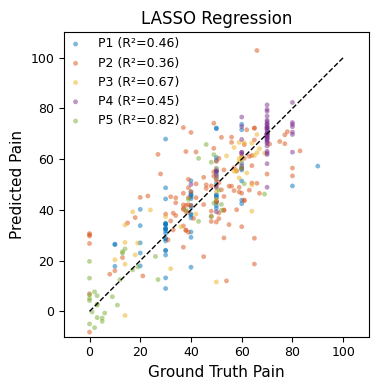

In [6]:
plot_lasso_scatter(model_config, data_dir, fig_dir, save_fig=True)

### Figure 3C, cohort-level LDA performance

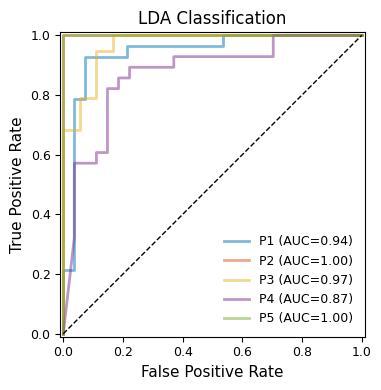

In [7]:
plot_lda_roc(model_config, data_dir, fig_dir, save_fig=True)

### Figures 3B & 3C statistics
Survey counts, score and permutation p-value of each model shown (as quoted in the Figure 3 legend). Each p-value is one-sided: the share of 1,000 label shuffles that scored above the real model, counting the real model once, so 1/1001 = 0.001 is the smallest possible.

In [8]:
rows = []
for pt, models in model_config.items():
    for method, (metric, window) in models.items():
        table = pd.read_excel(data_dir / 'figure3_processed_inpatient_pain_decoding' / f"{pt}_{method.lower()}_across_models.xlsx")
        row = table[(table['metric_org'] == metric) & (table['size_org'] == window)].iloc[0]
        if method == 'LASSO':
            n, score = f"{row['Num Samples']} surveys", f"R2 = {row['r-squared']:.2f}"
        else:
            n, score = f"{row['High Pain Samples']} high / {row['Low Pain Samples']} low", f"AUC = {row['auc']:.2f}"
        rows.append([pt, method, metric, window, n, score, f"{row['p_values']:.4f}"])
print(pd.DataFrame(rows, columns=['participant', 'method', 'metric', 'window', 'n', 'score', 'permutation p']).to_string(index=False))

participant method                metric        window                n      score permutation p
         P1  LASSO                nrs_s0   five_minute       70 surveys  R2 = 0.46        0.0010
         P1    LDA                nrs_s0   five_minute 28 high / 28 low AUC = 0.94        0.0010
         P2  LASSO unpleasantness_vas_s0    one_minute      121 surveys  R2 = 0.36        0.0010
         P2    LDA             relief_s0    ten_minute   4 high / 4 low AUC = 1.00        0.0010
         P3  LASSO      intensity_vas_s0 thirty_minute       40 surveys  R2 = 0.67        0.0010
         P3    LDA      intensity_vas_s0   five_minute 19 high / 18 low AUC = 0.97        0.0010
         P4  LASSO                nrs_s0    ten_minute       55 surveys  R2 = 0.45        0.0010
         P4    LDA      intensity_vas_s0    one_minute 28 high / 27 low AUC = 0.87        0.0010
         P5  LASSO      intensity_vas_s0    ten_minute       42 surveys  R2 = 0.82        0.0010
         P5    LDA      intens

### Figure 3D, Plot example (P3) feature counts by hemisphere

Plotting P3 feature prominence
    Left hemisphere: 10 regions
    Right hemisphere: 10 regions
    Saved: <repo>/figures/Figure3D.pdf


<repo>/python_code/shared_utilities/utility/figure3_inpatient_decoding_helpers.py:369: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='anatomy', y='count_combined', data=df, palette=colors, ax=ax)
<repo>/python_code/shared_utilities/utility/figure3_inpatient_decoding_helpers.py:369: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='anatomy', y='count_combined', data=df, palette=colors, ax=ax)


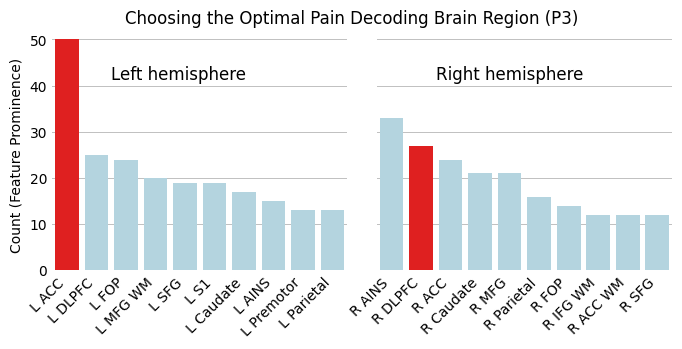

In [9]:
# specify which regions to set to red
mapping = {
    'P1': ([1], [2]),
    'P2': ([0], [0]),
    'P3': ([0], [1]),
    'P4': (None, None),
    'P5': (None, None),
}
# plot all specified participants
for pt in pt_labels:
    print(f"Plotting {pt} feature prominence")

    # P3 is the participant shown in Figure 3D, so its panel is saved to file.
    save_fig = (pt == 'P3')
    features_path = Path(data_dir) / 'figure3_processed_inpatient_pain_decoding' / f"{pt}_inpatient_feature_counts.xlsx"
    
    # Load feature counts data
    feature_counts = pd.read_excel(features_path)
    # Split by hemisphere
    left_df, right_df = split_by_hemisphere(feature_counts,TOP_N_REGIONS=10)
    # set certain regions to red based on final implant site
    ind_left, ind_right = mapping.get(pt, (None, None))
    # plot seperate hemispheres, but rank feature counts WITHIN hemisphere
    create_hemisphere_plot(left_df, right_df, pt, 
                           fig_dir/ 'Figure3D.pdf',
                           left_red_bars=ind_left,
                           right_red_bars=ind_right,
                           save_fig = save_fig)